## 1. Gradient descent dengan banyak input

Contoh menggunakan tiga input terkait pertandingan basket:
- `toes`: jumlah cedera jari kaki dalam data contoh.
- `wlrec`: catatan kemenangan/kekalahan.
- `nfans`: jumlah penggemar (nilai contoh).

Jaringan menghitung weighted sum dari seluruh input:

$
prediction=\sum_i input_i\,weight_i
$

Setiap input mempunyai weight masing-masing. Setelah prediksi dibandingkan dengan target, masing-masing weight diperbarui sesuai input yang terhubung dengannya.

In [1]:
def w_sum(a, b):
    assert len(a) == len(b)
    output = 0
    for i in range(len(a)):
        output += a[i] * b[i]
    return output

def neural_network(inputs, weights):
    return w_sum(inputs, weights)

toes = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]
win_or_lose_binary = [1, 1, 0, 1]

weights = [0.1, 0.2, -0.1]
inputs = [toes[0], wlrec[0], nfans[0]]
true = win_or_lose_binary[0]

pred = neural_network(inputs, weights)
error = (pred - true) ** 2
delta = pred - true

print("Inputs:", inputs)
print("Prediction:", pred)
print("Target:", true)
print("Squared error:", error)
print("Delta:", delta)

Inputs: [8.5, 0.65, 1.2]
Prediction: 0.8600000000000001
Target: 1
Squared error: 0.01959999999999997
Delta: -0.1399999999999999


## 2. Menghitung delta untuk setiap weight

Seluruh weight menuju output yang sama, sehingga menggunakan `delta` output yang sama. Namun, setiap weight terhubung dengan input berbeda, sehingga `weight_delta` masing-masing berbeda:

$
weight\_delta_i=delta\times input_i
$

Kemudian weight diperbarui dengan:

$
weight_i \leftarrow weight_i-\alpha\,weight\_delta_i
$

Ini adalah generalisasi langsung dari gradient descent pada satu weight.

In [2]:
def ele_mul(number, vector):
    output = [0 for _ in vector]
    for i in range(len(vector)):
        output[i] = number * vector[i]
    return output

weights = [0.1, 0.2, -0.1]
inputs = [toes[0], wlrec[0], nfans[0]]
true = win_or_lose_binary[0]
alpha = 0.01

pred = neural_network(inputs, weights)
delta = pred - true
weight_deltas = ele_mul(delta, inputs)

for i in range(len(weights)):
    weights[i] -= alpha * weight_deltas[i]

print("Prediction before update:", pred)
print("Delta:", delta)
print("Weight deltas:", weight_deltas)
print("Updated weights:", weights)

Prediction before update: 0.8600000000000001
Delta: -0.1399999999999999
Weight deltas: [-1.189999999999999, -0.09099999999999994, -0.16799999999999987]
Updated weights: [0.1119, 0.20091, -0.09832]


## 4. Melihat beberapa langkah pembelajaran

Pembaruan weight dilakukan berulang. Setiap iterasi menghitung prediksi baru menggunakan weight yang sudah diperbarui, kemudian menghitung delta dan memperbarui weight lagi.

Contoh ini menggunakan satu datapoint per iterasi (*stochastic gradient descent* dalam arti pembaruan dilakukan dari satu datapoint pada satu waktu).

In [3]:
toes = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]
targets = [1, 1, 0, 1]

weights = [0.1, 0.2, -0.1]
alpha = 0.01

print("step | prediction | target | squared error | weights")
for i in range(len(targets)):
    inputs = [toes[i], wlrec[i], nfans[i]]
    pred = neural_network(inputs, weights)
    delta = pred - targets[i]
    error = delta ** 2
    weight_deltas = ele_mul(delta, inputs)
    weights = [w - alpha * wd for w, wd in zip(weights, weight_deltas)]
    print(f"{i+1:4d} | {pred:10.4f} | {targets[i]:6.1f} | {error:13.4f} | {weights}")

step | prediction | target | squared error | weights
   1 |     0.8600 |    1.0 |        0.0196 | [0.1119, 0.20091, -0.09832]
   2 |     1.0960 |    1.0 |        0.0092 | [0.10278360999999998, 0.200142304, -0.099567506]
   3 |     1.1279 |    0.0 |        1.2721 | [-0.008877285090800005, 0.19111920136639998, -0.105206945146]
   4 |    -0.0131 |    1.0 |        1.0264 | [0.08230128558520962, 0.20023705843400094, -0.0950759928486656]


## 5. Freezing one weight

*Freezing one weight* berarti menahan satu weight agar tidak diperbarui, sementara weight lain tetap belajar. Ini membantu mengamati bagaimana kontribusi suatu input berubah ketika weight-nya tidak ikut menyesuaikan diri.

Pada latihan ini, weight indeks `0` dibekukan. Weight lain diperbarui dengan aturan yang sama.

In [ ]:
weights = [0.1, 0.2, -0.1]
alpha = 0.01
frozen_index = 0

inputs = [toes[0], wlrec[0], nfans[0]]
true = win_or_lose_binary[0]

pred = neural_network(inputs, weights)
delta = pred - true
weight_deltas = ele_mul(delta, inputs)

for i in range(len(weights)):
    if i != frozen_index:
        weights[i] -= alpha * weight_deltas[i]

print("Frozen weight index:", frozen_index)
print("Weight deltas:", weight_deltas)
print("Weights after update:", weights)
print("Notice that weights[0] remains 0.1.")

## 6. Gradient descent dengan banyak output

Satu input dapat dipakai untuk membuat beberapa prediksi. Dalam contoh buku, catatan kemenangan/kekalahan dipakai untuk memprediksi tiga keluaran: `hurt`, `win`, dan `sad`.

Setiap output memiliki weight sendiri. Karena itu, setiap output juga memiliki `delta` sendiri. Untuk satu input yang sama:

$
weight\_delta_i=delta_i\times input
$

Setiap weight diperbarui menggunakan delta dari output yang terhubung dengannya.

In [4]:
def scalar_ele_mul(number, vector):
    return [number * value for value in vector]

def neural_network_multi_output(input_value, weights):
    return scalar_ele_mul(input_value, weights)

wlrec = [0.65, 1.0, 1.0, 0.9]
hurt = [0.1, 0.0, 0.0, 0.1]
win = [1, 1, 0, 1]
sad = [0.1, 0.0, 0.1, 0.2]

weights = [0.3, 0.2, 0.9]
input_value = wlrec[0]
true = [hurt[0], win[0], sad[0]]
pred = neural_network_multi_output(input_value, weights)
deltas = [p - t for p, t in zip(pred, true)]
errors = [(p - t) ** 2 for p, t in zip(pred, true)]

print("Output order: hurt, win, sad")
print("Predictions:", pred)
print("Targets:", true)
print("Squared errors:", errors)
print("Deltas:", deltas)

Output order: hurt, win, sad
Predictions: [0.195, 0.13, 0.5850000000000001]
Targets: [0.1, 1, 0.1]
Squared errors: [0.009025, 0.7569, 0.2352250000000001]
Deltas: [0.095, -0.87, 0.4850000000000001]


In [5]:
alpha = 0.01
weight_deltas = scalar_ele_mul(1, deltas)  # satu input dipakai bersama untuk semua output
weight_deltas = [delta * input_value for delta in deltas]
updated_weights = [w - alpha * wd for w, wd in zip(weights, weight_deltas)]

print("Input:", input_value)
print("Weight deltas:", weight_deltas)
print("Weights before:", weights)
print("Weights after:", updated_weights)

Input: 0.65
Weight deltas: [0.061750000000000006, -0.5655, 0.3152500000000001]
Weights before: [0.3, 0.2, 0.9]
Weights after: [0.2993825, 0.205655, 0.8968475]


## 7. Banyak input dan banyak output

Untuk menggabungkan beberapa input dan beberapa output, setiap output memiliki satu weight untuk setiap input. Struktur weight menjadi matriks: setiap baris mewakili satu output dan setiap kolom mewakili satu input.

Prediksi untuk setiap output adalah weighted sum dari input. Pembaruan tiap weight menggunakan `delta` output yang sesuai dikalikan input yang terhubung dengannya.

In [6]:
weights = [
    [0.1, 0.1, -0.3],  # hurt
    [0.1, 0.2,  0.0],  # win
    [0.0, 1.3,  0.1]   # sad
]

def neural_network_multi_input_output(inputs, weights):
    return [w_sum(inputs, row) for row in weights]

inputs = [toes[0], wlrec[0], nfans[0]]
predictions = neural_network_multi_input_output(inputs, weights)
print("Inputs:", inputs)
print("Predictions [hurt, win, sad]:", predictions)

Inputs: [8.5, 0.65, 1.2]
Predictions [hurt, win, sad]: [0.555, 0.9800000000000001, 0.9650000000000001]


In [7]:
targets = [0.2, 1.0, 0.1]
alpha = 0.01

predictions = neural_network_multi_input_output(inputs, weights)
deltas = [p - t for p, t in zip(predictions, targets)]
weight_deltas = [
    [deltas[out_i] * inputs[in_i] for in_i in range(len(inputs))]
    for out_i in range(len(weights))
]

updated_weights = [
    [weights[o][i] - alpha * weight_deltas[o][i] for i in range(len(inputs))]
    for o in range(len(weights))
]

print("Predictions:", predictions)
print("Targets:", targets)
print("Deltas:", deltas)
print("Weight deltas:")
for row in weight_deltas:
    print(row)
print("Updated weight matrix:")
for row in updated_weights:
    print(row)

Predictions: [0.555, 0.9800000000000001, 0.9650000000000001]
Targets: [0.2, 1.0, 0.1]
Deltas: [0.35500000000000004, -0.019999999999999907, 0.8650000000000001]
Weight deltas:
[3.0175000000000005, 0.23075000000000004, 0.42600000000000005]
[-0.1699999999999992, -0.01299999999999994, -0.023999999999999886]
[7.352500000000001, 0.5622500000000001, 1.038]
Updated weight matrix:
[0.069825, 0.0976925, -0.30426]
[0.1017, 0.20013, 0.00023999999999999887]
[-0.07352500000000001, 1.2943775, 0.08962]


## 8. Memvisualisasikan nilai weight

Weight menunjukkan seberapa besar dan ke arah mana input memengaruhi weighted sum output. Nilai positif menambah kontribusi untuk input positif, nilai negatif mengurangi kontribusi. Nilai weight tidak boleh ditafsirkan terpisah dari skala input dan struktur model.

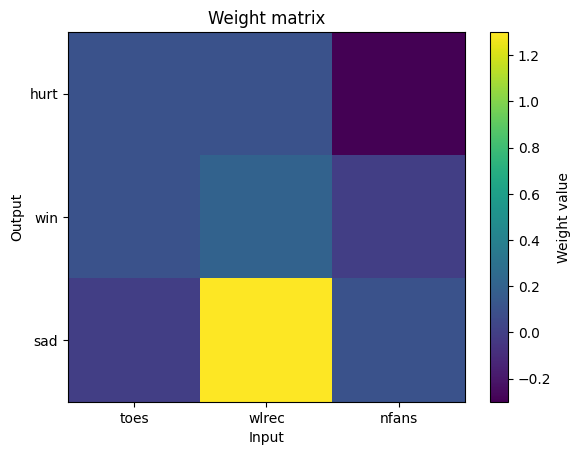

In [8]:
import matplotlib.pyplot as plt
import numpy as np

weight_matrix = np.array([
    [0.1, 0.1, -0.3],
    [0.1, 0.2, 0.0],
    [0.0, 1.3, 0.1]
])

plt.imshow(weight_matrix, aspect="auto")
plt.colorbar(label="Weight value")
plt.xticks(range(3), ["toes", "wlrec", "nfans"])
plt.yticks(range(3), ["hurt", "win", "sad"])
plt.title("Weight matrix")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()

## 9. Dot product sebagai weighted sum dan ukuran kemiripan

Dot product mengalikan elemen yang bersesuaian dari dua vektor lalu menjumlahkan hasilnya:

$
a\cdot b=\sum_i a_i b_i
$

Jika dua vektor mempunyai nilai positif pada posisi yang sama, dot product-nya dapat lebih besar. Dalam konteks jaringan, dot product input dan weight menghasilkan weighted sum yang menjadi prediksi atau skor output. Ini dapat dipahami sebagai ukuran kemiripan sederhana, tetapi bukan ukuran kemiripan universal untuk semua situasi.

In [9]:
import numpy as np

a = np.array([0, 1, 0, 1])
b = np.array([1, 0, 1, 0])
c = np.array([0, 1, 1, 0])
d = np.array([0.5, 0, 0.5, 0])

print("a · b =", np.dot(a, b))
print("c · d =", np.dot(c, d))
print("c · c =", np.dot(c, c))

a · b = 0
c · d = 0.5
c · c = 2
